In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("../data/transactions.csv", parse_dates=["TransactionTime"])
print(df.shape)
df.info()
df.head()

(50060, 9)
<class 'pandas.DataFrame'>
RangeIndex: 50060 entries, 0 to 50059
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   TransactionID         50060 non-null  str           
 1   Amount                49910 non-null  float64       
 2   TransactionTime       50060 non-null  datetime64[us]
 3   MerchantCategory      50060 non-null  str           
 4   CustomerAge           49559 non-null  float64       
 5   PreviousTransactions  50060 non-null  int64         
 6   FailedAttempts        50060 non-null  int64         
 7   Location              49810 non-null  str           
 8   IsFraud               50060 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(3), str(3)
memory usage: 3.4 MB


,TransactionID,Amount,TransactionTime,MerchantCategory,CustomerAge,PreviousTransactions,FailedAttempts,Location,IsFraud
0,TXN126684,227.31,2025-01-09 16:50:18,Fuel,50.0,46,0,Pune,0
1,TXN131838,700.80,2025-12-20 04:00:44,Grocery,41.0,39,1,Bengaluru,0
2,TXN106788,87.50,2025-02-10 05:05:22,Restaurant,39.0,38,0,Vadodara,0
3,TXN138746,532.88,2025-01-29 23:33:41,Travel,41.0,43,0,Bengaluru,0
4,TXN109848,924.71,2025-07-13 04:15:25,Fuel,48.0,39,0,Hyderabad,0


In [2]:
print("Missing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate TransactionIDs:", df["TransactionID"].duplicated().sum())
print("Negative amounts:", (df["Amount"] < 0).sum())
df.describe()

Missing values:
 TransactionID             0
Amount                  150
TransactionTime           0
MerchantCategory          0
CustomerAge             501
PreviousTransactions      0
FailedAttempts            0
Location                250
IsFraud                   0
dtype: int64

Duplicate rows: 60
Duplicate TransactionIDs: 60
Negative amounts: 10


,Amount,TransactionTime,CustomerAge,PreviousTransactions,FailedAttempts,IsFraud
count,49910.000000,50060,49559.000000,50060.000000,50060.000000,50060.000000
mean,740.513640,2025-07-02 06:30:39.636915,37.816118,31.852018,0.247343,0.025190
min,-4003.050000,2025-01-01 00:00:27,18.000000,0.000000,0.000000,0.000000
25%,191.730000,2025-04-01 18:06:10.500000,29.000000,29.000000,0.000000,0.000000
50%,398.675000,2025-07-02 15:50:16,38.000000,34.000000,0.000000,0.000000
75%,841.105000,2025-10-01 10:05:47.750000,46.000000,38.000000,0.000000,0.000000
max,99504.560000,2025-12-31 23:50:47,85.000000,58.000000,4.000000,1.000000
std,1252.784338,NaN,11.481452,11.030229,0.496565,0.156703


Fraud: 2.52%  |  Legit: 97.48%
IsFraud
0    48799
1     1261
Name: count, dtype: int64


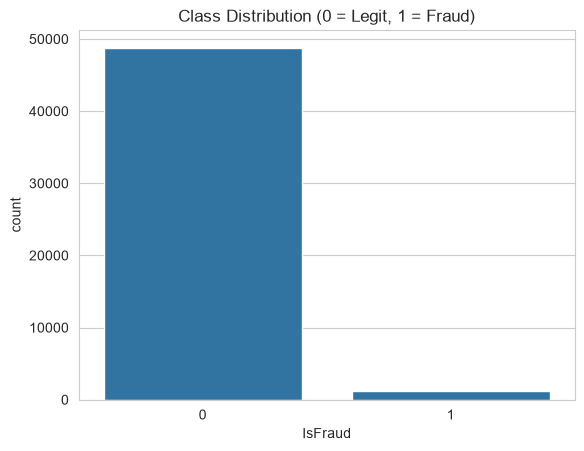

In [3]:
fraud_pct = df["IsFraud"].mean() * 100
print(f"Fraud: {fraud_pct:.2f}%  |  Legit: {100 - fraud_pct:.2f}%")
print(df["IsFraud"].value_counts())

sns.countplot(x="IsFraud", data=df)
plt.title("Class Distribution (0 = Legit, 1 = Fraud)")
plt.show()

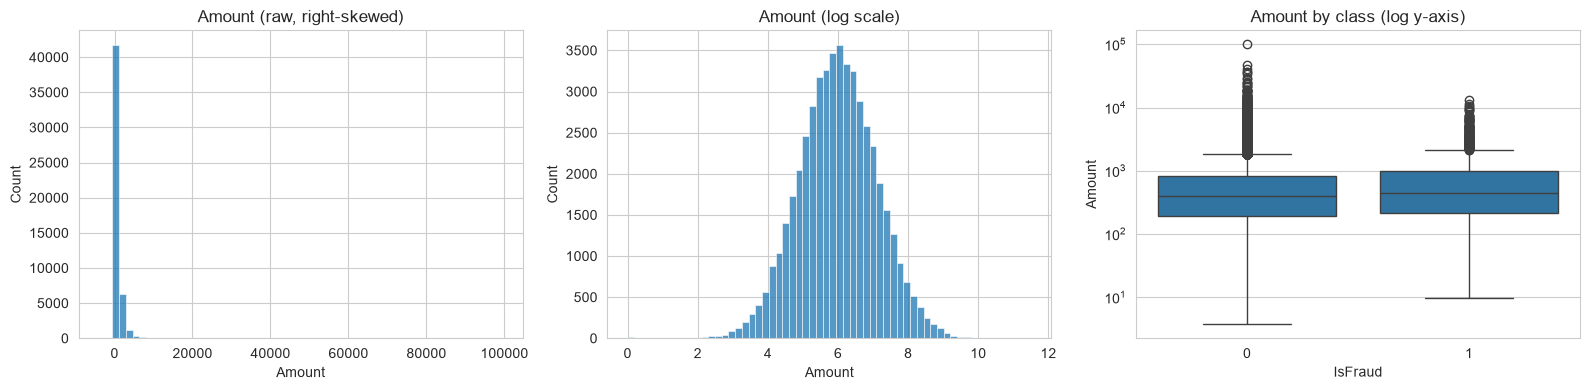

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Amount"].dropna(), bins=60, ax=axes[0])
axes[0].set_title("Amount (raw, right-skewed)")

sns.histplot(np.log1p(df["Amount"].clip(lower=0).dropna()), bins=60, ax=axes[1])
axes[1].set_title("Amount (log scale)")

sns.boxplot(x="IsFraud", y="Amount", data=df[df["Amount"] > 0], ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Amount by class (log y-axis)")

plt.tight_layout()
plt.show()

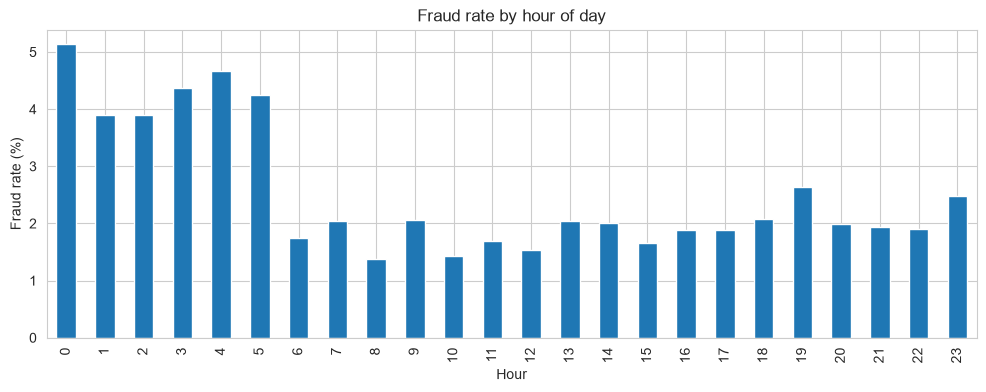

In [5]:
df["Hour"] = df["TransactionTime"].dt.hour
df["IsNight"] = df["Hour"].between(0, 5).astype(int)

hourly = df.groupby("Hour")["IsFraud"].mean() * 100
hourly.plot(kind="bar", figsize=(12, 4))
plt.ylabel("Fraud rate (%)")
plt.title("Fraud rate by hour of day")
plt.show()

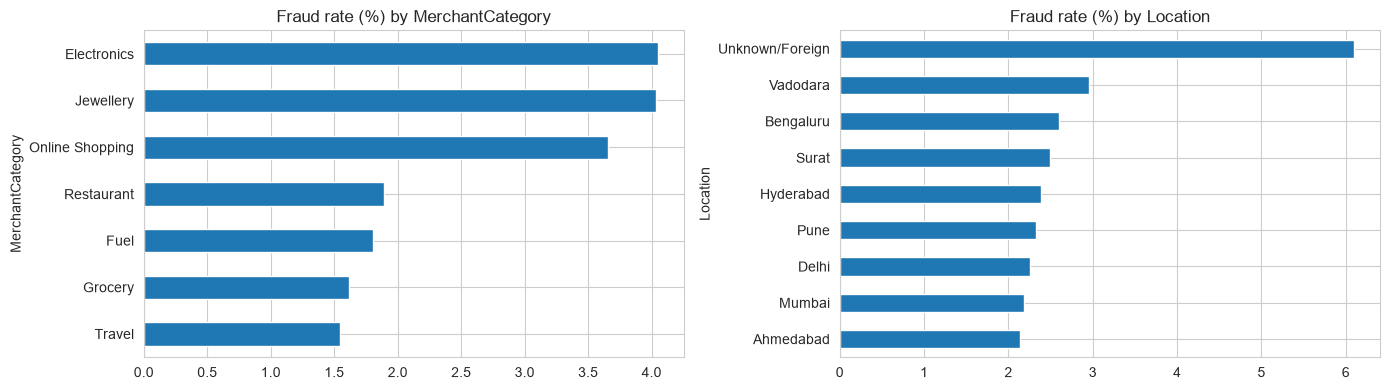

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

(df.groupby("MerchantCategory")["IsFraud"].mean() * 100).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Fraud rate (%) by MerchantCategory")

(df.groupby("Location")["IsFraud"].mean() * 100).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Fraud rate (%) by Location")

plt.tight_layout()
plt.show()

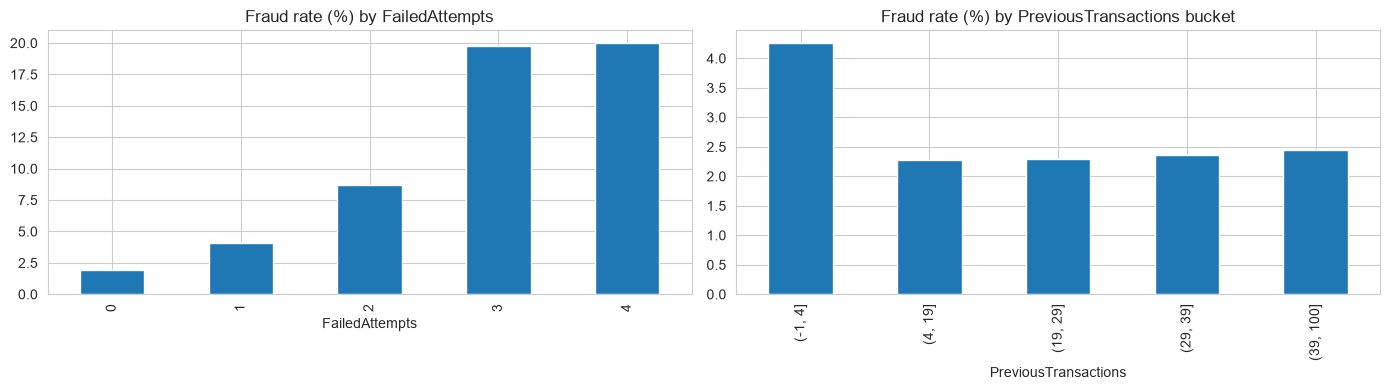

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

(df.groupby("FailedAttempts")["IsFraud"].mean() * 100).plot(kind="bar", ax=axes[0])
axes[0].set_title("Fraud rate (%) by FailedAttempts")

prev_bucket = pd.cut(df["PreviousTransactions"], bins=[-1, 4, 19, 29, 39, 100])
(df.groupby(prev_bucket, observed=True)["IsFraud"].mean() * 100).plot(kind="bar", ax=axes[1])
axes[1].set_title("Fraud rate (%) by PreviousTransactions bucket")

plt.tight_layout()
plt.show()

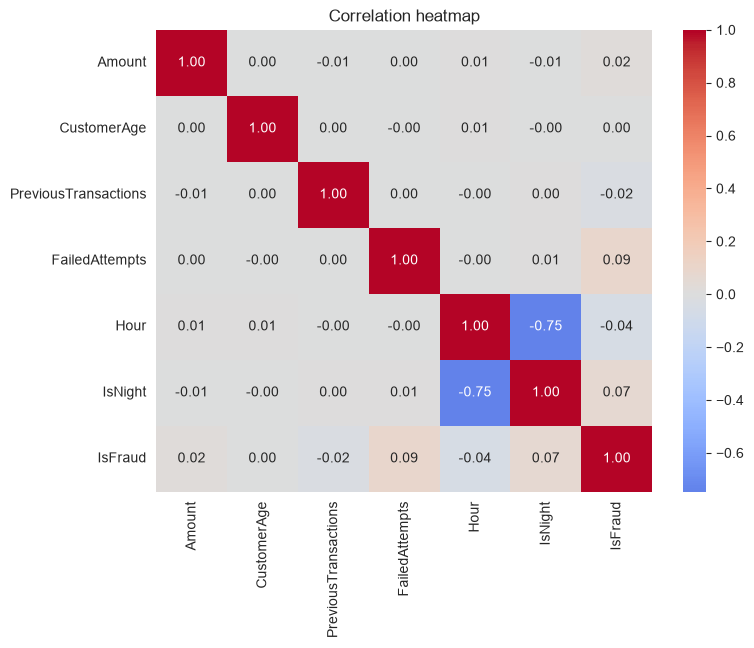

In [8]:
num_cols = ["Amount", "CustomerAge", "PreviousTransactions", "FailedAttempts", "Hour", "IsNight", "IsFraud"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [9]:
overall = df["IsFraud"].mean() * 100
night = df[df["IsNight"] == 1]["IsFraud"].mean() * 100
day = df[df["IsNight"] == 0]["IsFraud"].mean() * 100
cat = (df.groupby("MerchantCategory")["IsFraud"].mean() * 100).sort_values(ascending=False)
loc = (df.groupby("Location")["IsFraud"].mean() * 100).sort_values(ascending=False)
fa0 = df[df["FailedAttempts"] == 0]["IsFraud"].mean() * 100
fa2 = df[df["FailedAttempts"] >= 2]["IsFraud"].mean() * 100
new = df[df["PreviousTransactions"] < 5]["IsFraud"].mean() * 100
old = df[df["PreviousTransactions"] >= 5]["IsFraud"].mean() * 100
valid = df[df["Amount"] > 0]
med_f = valid[valid["IsFraud"] == 1]["Amount"].median()
med_l = valid[valid["IsFraud"] == 0]["Amount"].median()

summary = f"""## EDA Findings

**Class imbalance:** Only {overall:.2f}% of transactions are fraudulent ({df['IsFraud'].sum()} of {len(df)}). Accuracy alone is misleading, so I use Precision, Recall, F1, ROC-AUC and PR-AUC, and handle imbalance with class weights.

**Data quality:** {df.duplicated().sum()} duplicate rows, {(df['Amount'] < 0).sum()} negative amounts (invalid), and missing values in Amount ({df['Amount'].isna().sum()}), CustomerAge ({df['CustomerAge'].isna().sum()}) and Location ({df['Location'].isna().sum()}). Amount is heavily right-skewed (max {df['Amount'].max():,.0f} vs median {df['Amount'].median():,.0f}), so a log transform is used.

### Potential fraud indicators
1. **Night-time transactions (00:00-05:59):** fraud rate {night:.2f}% at night vs {day:.2f}% during the day.
2. **Failed attempts:** fraud rate {fa2:.2f}% with 2+ failed attempts vs {fa0:.2f}% with none.
3. **Merchant category:** highest fraud rate in {cat.index[0]} ({cat.iloc[0]:.2f}%) and {cat.index[1]} ({cat.iloc[1]:.2f}%); lowest in {cat.index[-1]} ({cat.iloc[-1]:.2f}%).
4. **Location:** {loc.index[0]} has the highest fraud rate ({loc.iloc[0]:.2f}%).
5. **New customers (fewer than 5 previous transactions):** fraud rate {new:.2f}% vs {old:.2f}% for established customers.
6. **Amount:** median fraud amount is {med_f:,.0f} vs {med_l:,.0f} for legitimate transactions.

### Limitations of the data
- The dataset is **synthetic**; fraud was generated from hand-written rules plus noise, so real-world fraud will be messier and model scores here are likely optimistic.
- Fraud is rare (about {overall:.1f}%), so there are few positive examples to learn from.
- Only one year of data (2025) and no customer or card identifier, so no per-customer behaviour history (velocity, spending habits) can be built.
- Location is a coarse city label; no merchant ID, device, IP or distance-from-home features.
- Labels may be noisy or delayed in real systems (fraud is often confirmed weeks later).
- Correlation is not causation; these indicators describe patterns, not proof of fraud.
"""
print(summary)

## EDA Findings

**Class imbalance:** Only 2.52% of transactions are fraudulent (1261 of 50060). Accuracy alone is misleading, so I use Precision, Recall, F1, ROC-AUC and PR-AUC, and handle imbalance with class weights.

**Data quality:** 60 duplicate rows, 10 negative amounts (invalid), and missing values in Amount (150), CustomerAge (501) and Location (250). Amount is heavily right-skewed (max 99,505 vs median 399), so a log transform is used.

### Potential fraud indicators
1. **Night-time transactions (00:00-05:59):** fraud rate 4.37% at night vs 1.91% during the day.
2. **Failed attempts:** fraud rate 9.58% with 2+ failed attempts vs 1.90% with none.
3. **Merchant category:** highest fraud rate in Electronics (4.05%) and Jewellery (4.03%); lowest in Travel (1.54%).
4. **Location:** Unknown/Foreign has the highest fraud rate (6.10%).
5. **New customers (fewer than 5 previous transactions):** fraud rate 4.26% vs 2.37% for established customers.
6. **Amount:** median fraud amount is 